(sec:dispersion)=
# Dispersion interactions

## Long-range interaction energy

The interaction energy between two molecular systems $A$ and $B$ is given by

$$
\Delta E = E_\mathrm{AB} - E_\mathrm{A} - E_\mathrm{B}
$$

For charge neutral, nonpolar, systems separated by a sufficiently large distance $R$ this interaction energy is known as dispersion (or [van der Waals](https://en.wikipedia.org/wiki/Van_der_Waals_force)) energy.

## Dispersion and correlation



The prototypical system exemplifying dispersion interactions is the  He dimer for which the interaction energy equals

$$
\Delta E(R) = E_\mathrm{dimer} - 2E_\mathrm{He}
$$

We will determine this interaction energy with respect to the interatomic separation distance at the Hartree–Fock and MP2 levels of theory.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy
import veloxchem as vlx

au2ang = 0.529177

atom_xyz = """1
He atom
He    0.000000000000        0.000000000000        0.000000000000
"""

dimer_xyz = """2
He dimer
He    0.000000000000        0.000000000000        0.000000000000
He    0.000000000000        0.000000000000        dimer_separation
"""

In [2]:
atom = vlx.Molecule.read_xyz_string(atom_xyz)
atom_basis = vlx.MolecularBasis.read(atom, "aug-cc-pvtz", ostream=None)

dimer = vlx.Molecule.read_xyz_string(dimer_xyz.replace("dimer_separation", "5.0"))
dimer_basis = vlx.MolecularBasis.read(dimer, "aug-cc-pvtz", ostream=None)

Determine the atomic energies the HF and MP2 levels of theory.

In [3]:
scf_drv = vlx.ScfRestrictedDriver()
mp2_drv = vlx.mp2driver.Mp2Driver()
scf_drv.ostream.mute()
mp2_drv.ostream.mute()

scf_results = scf_drv.compute(atom, atom_basis)
hf_atom_energy = scf_drv.get_scf_energy()

mp2_results = mp2_drv.compute(atom, atom_basis, scf_drv.mol_orbs)
mp2_atom_energy = hf_atom_energy + mp2_results["mp2_energy"]

Determine the dimer energies over a range of interatomic separation distance.

In [4]:
distances = np.linspace(2.75, 5.0, 10)
hf_dimer_energies = []
mp2_dimer_energies = []

for dist in distances:

    dimer = vlx.Molecule.read_xyz_string(
        dimer_xyz.replace("dimer_separation", str(dist))
    )

    scf_results = scf_drv.compute(dimer, dimer_basis)
    hf_dimer_energies.append(scf_drv.get_scf_energy())
    mp2_results = mp2_drv.compute(dimer, dimer_basis, scf_drv.mol_orbs)
    mp2_dimer_energies.append(scf_drv.get_scf_energy() + mp2_results["mp2_energy"])

hf_dimer_energies = np.array(hf_dimer_energies)
mp2_dimer_energies = np.array(mp2_dimer_energies)

Plot the interaction energies in units of micro-Hartree.

In [5]:
hf_interaction_energies = hf_dimer_energies - 2 * hf_atom_energy
mp2_interaction_energies = mp2_dimer_energies - 2 * mp2_atom_energy

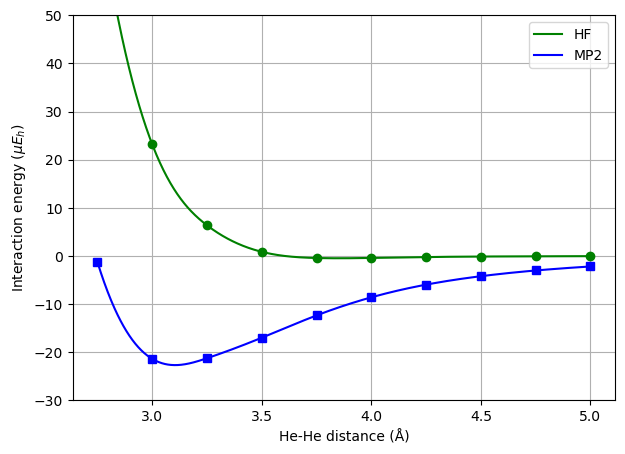

In [6]:
R = np.linspace(2.75, 5.0, 1000)

plt.figure(figsize=(7, 5))
x, y = distances, hf_interaction_energies * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "g-", label="HF")
plt.plot(x, y, "go")

x, y = distances, mp2_interaction_energies * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "b-", label="MP2")
plt.plot(x, y, "bs")

plt.xlabel("He-He distance (Å)")
plt.ylabel(r"Interaction energy ($\mu E_h$)")
plt.ylim(-30, 50)
plt.legend()
plt.grid(True)
plt.show()

The failure of the HF method to describe the minimum of the potential energy curve for the helium dimer is due to the lack of correlation. More specifically, let us consider a system setup where the $z$-axis is chosen as the internuclear axis and the helium atoms are placed at $z = 0$ and $z=R_0$, respectively (see the inset in the figure below). We will then be concerned with the [two-particle density](#sec:two_particle_density_operator), $n(\mathbf{r}_1, \mathbf{r}_2)$, at coordinates

$$
\begin{align}
\mathbf{r}_1 & = (d, 0,0) \\
\mathbf{r}_2 & = (d \cos\theta, d \sin\theta,R_0) \\
\end{align}
$$

At the HF level of theory, the two-particle density will be independent of the angle $\theta$ whereas this is not the case when electron correlation is accounted for. The MP2 density shows a maximum when the two electrons are positioned as far apart as possible, or in other words as $\theta = 180^\circ$. 

![Two-particle density He dimer](../../img/misc/he_dimer.svg)

This asymmetry in the two-particle density is referred to as fluctuating induced dipoles, or instantaneous dipole–dipole interactions, and it is the source origin of the weakly attractive van der Waals energies.

## Dispersion by perturbation theory

The long-range interaction energy between two randomly oriented molecules $A$ and $B$ is given by the Casimir–Polder potential

\begin{align}
  \Delta E(R) & = - \frac{\hbar}{\pi R^6} \int_{0}^{\infty} 
  \overline{\alpha}_A(i\omega^I)
  \overline{\alpha}_B(i\omega^I)
  e^{-2\omega^I R/c} 
  \\ & \quad \times
\left[
    3 + 6 \frac{\omega^I R}{c} 
    + 5 \left(\frac{\omega^I R}{c}\right)^2
    + 2 \left(\frac{\omega^I R}{c}\right)^3
    + \left(\frac{\omega^I R}{c}\right)^4
\right]
d\omega^I
\end{align}

where $R$ is the intermolecular separation, $c$ is the speed of light, and $\overline{\alpha}_A(i\omega^I)$ is the isotropic average of the electric dipole polarizability tensor of molecule $A$ evaluated at a purely imaginary frequency. The molecules are here considered to be polarizable entities. Additional contributions to the energy will arise from higher-order electric multipole interactions as well as magnetic interactions. 

The interaction energy is often expressed in terms of dispersion coefficients $C_m$, where $m = 6, 8, 10, \ldots$, and long-range coefficients $K_n$, where $n = 7, 9, 11, \ldots$, so that, in the van der Waals region, we have

$$
\Delta E(R) = -\frac{C_6}{R^6} -\frac{C_8}{R^8}
  -\frac{C_{10}}{R^{10}} - \cdots 
$$

and, at very large intermolecular separation, we have 

$$
  \Delta E(R) = -\frac{K_7}{R^7} -\frac{K_9}{R^9}
  -\frac{K_{11}}{R^{11}} -  \cdots 
$$

The reason for the deviation of the interaction energy at large $R$ from a $1/R^6$ dependence, as given by London–van der Waals dispersion theory, is the finite speed of the photons mediating the electromagnetic interaction, or, equivalently, retardation.

The leading dispersion coefficient is given by

\begin{equation}
  C_6 =
  \frac{3\hbar}{\pi} \int_{0}^{\infty} 
  \overline{\alpha}_A(i\omega)
  \overline{\alpha}_B(i\omega) d\omega  
\end{equation}


In [7]:
c6_drv = vlx.C6Driver()
c6_drv.ostream.mute()
scf_results = scf_drv.compute(atom, atom_basis)
c6_results = c6_drv.compute(atom, atom_basis, scf_results)

hf_c6 = c6_results["c6"]

Based on Hartree–Fock data and with access to the $C_6$ dispersion coefficient, a much more realistic potential energy curve can be constructed as follows

\begin{equation}
\Delta E(R) = \Delta E^\mathrm{HF}(R) -
\frac{C_6}{R^6}
\end{equation}

where the first and second term contribute the repulsive and attractive parts of the potential, respectively.

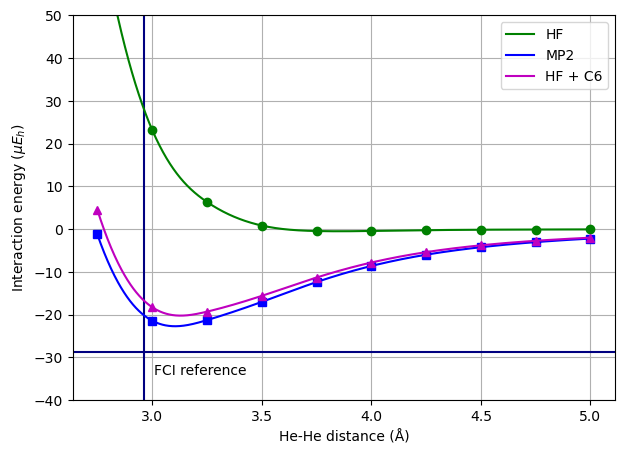

In [8]:
plt.figure(figsize=(7, 5))

# Reference data at FCI level
plt.axvline(5.6 * au2ang, color="navy")
plt.axhline(-28.76, color="navy")
plt.text(3.01, -34, "FCI reference")

x, y = distances, hf_interaction_energies * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "g-", label="HF")
plt.plot(x, y, "go")

x, y = distances, mp2_interaction_energies * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "b-", label="MP2")
plt.plot(x, y, "bs")

x, y = distances, (hf_interaction_energies - hf_c6 / (distances / au2ang) ** 6) * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "m-", label="HF + C6")
plt.plot(x, y, "m^")

plt.xlabel("He-He distance (Å)")
plt.ylabel(r"Interaction energy ($\mu E_h$)")
plt.ylim(-40, 50)
plt.legend()
plt.grid(True)
plt.show()

A FCI reference value for the binding energy, 29 $\mu E_h$, and equilibrium distance, 2.96 Å {cite}`vos90`, is depicted in the figure as the crossing point of the vertical and horizontal lines. Both the MP2 and the dispersion-corrected HF minima are quite close to this FCI reference point.

It has become a standard procedure to adopt a similar approach to add dispersion corrections to DFT potentials as standard functionals do not offer an inclusion of dispersion interactions. This can be very important when performing molecular structure optimizations of systems with nonbonded interactions.

## Dispersion by symmetry-adapted perturbation theory (SAPT)

In the supermolecular approach above, the weak interaction energy is obtained as a small difference between large total energies---and nothing in the calculation tells us *which* physical effects make up the result. Symmetry-adapted perturbation theory (SAPT) {cite}`sapt1994` instead treats the interaction between the monomers as a perturbation---the zeroth-order problem being the two isolated monomers---and the interaction energy is obtained directly, order by order, as a sum of physically distinct contributions. At the lowest level, known as SAPT0, the monomers are described at the HF level and the interaction operator is treated to second order

\begin{equation}
\Delta E^\mathrm{SAPT0} = E^{(10)}_\mathrm{elst} + E^{(10)}_\mathrm{exch} + E^{(20)}_\mathrm{ind} + E^{(20)}_\mathrm{exch-ind} + E^{(20)}_\mathrm{disp} + E^{(20)}_\mathrm{exch-disp}
\end{equation}

where the first superscript gives the order in the *inter*molecular interaction and the second the order in the *intra*monomer correlation, which we keep at zerohere. The terms are

- **Electrostatics**, the classical Coulomb interaction between the unperturbed HF charge distributions of the monomers, nuclei included.
- **Exchange**, the Pauli repulsion that arises when the dimer wavefunction is antisymmetrized with respect to exchange of electrons *between* the monomers. Note that it is here evaluated in the single-exchange, or $S^2$, approximation.
- **Induction**, the energy lowering due to the polarization of each monomer in the static field of the other, obtained from the CPHF equations.
- **Exchange--induction**, the exchange counterpart of induction, which quenches it at short range.
- **Dispersion**, the attraction due to correlated fluctuations of the two charge distributions. This is exactly the effect that is absent at the HF level and that we discussed above in terms of the two-particle density.

The exchange--dispersion term and the so-called $\delta$HF correction, which collects higher-order induction effects from a supermolecular HF calculation, are left out in the implementation below.

There is no SAPT driver in VeloxChem, but all terms can be assembled from the integrals supplies together with the monomer HF solutions. Each monomer is computed in the full dimer basis set by placing ghost basis functions (`Bq`) on the partner atom---the standard practice in SAPT. The equations are collected below, and the implementation is found in the code cell that follows, and are based on {cite}`xie2022`.

With ${\mathbf{C}^X_\mathrm{occ}}$ and ${\mathbf{C}^X_\mathrm{vir}}$ denoting the occupied and virtual MO coefficients of monomer $X$, we define the AO density matrices ${\mathbf{P}^X = \mathbf{C}^X_\mathrm{occ} \mathbf{C}^{X\dagger}_\mathrm{occ}}$ and ${\mathbf{P}^X_\mathrm{vir} = \mathbf{C}^X_\mathrm{vir} \mathbf{C}^{X\dagger}_\mathrm{vir}}$, the Coulomb and exchange matrices ${\mathbf{J}[\mathbf{D}]_{\mu\nu} = \sum_{\lambda\sigma} D_{\lambda\sigma} (\mu\nu|\lambda\sigma)}$ and ${\mathbf{K}[\mathbf{D}]_{\mu\nu} = \sum_{\lambda\sigma} D_{\lambda\sigma} (\mu\lambda|\nu\sigma)}$, the electrostatic potential of monomer $X$, ${\boldsymbol{\omega}^X = \mathbf{V}^X + 2\mathbf{J}[\mathbf{P}^X]}$, with $\mathbf{V}^X$ the nuclear attraction matrix of $X$, as well as ${\mathbf{h}^X = \boldsymbol{\omega}^X - \mathbf{K}[\mathbf{P}^X]}$ and ${\mathbf{O} = \mathbf{P}^A \mathbf{S} \mathbf{P}^B}$, where $\mathbf{S}$ is the AO overlap matrix. With ${\mathbf{A} \cdot \mathbf{B} = \sum_{\mu\nu} A_{\mu\nu} B_{\mu\nu} }$ and $V_\mathrm{nuc}$ the nuclear repulsion between the monomers, the first-order terms read

\begin{align}
E^{(10)}_\mathrm{elst} &= 2\, \mathbf{P}^A \cdot \mathbf{V}^B + 2\, \mathbf{P}^B \cdot \mathbf{V}^A + 4\, \mathbf{P}^B \cdot \mathbf{J}[\mathbf{P}^A] + V_\mathrm{nuc} \\
E^{(10)}_\mathrm{exch}(S^2) &= -2\, (\mathbf{P}^A \mathbf{S} \mathbf{P}^B \mathbf{S} \mathbf{P}^A_\mathrm{vir}) \cdot \boldsymbol{\omega}^B - 2 \, (\mathbf{P}^B \mathbf{S} \mathbf{P}^A \mathbf{S} \mathbf{P}^B_\mathrm{vir}) \cdot \boldsymbol{\omega}^A \\ &\hphantom{=} \hspace{1mm} -2 \hspace{-.1mm} (\mathbf{P}^A_\mathrm{vir} \mathbf{S} \mathbf{P}^B) \cdot \mathbf{K}[\mathbf{P}^A \mathbf{S} \mathbf{P}^B_\mathrm{vir}]
\end{align}

The induction energy requires the response of monomer $A$ to the field of $B$, with $\tilde{\boldsymbol{\omega}}^B = \mathbf{C}^{A\dagger}_\mathrm{occ} \boldsymbol{\omega}^B \mathbf{C}^A_\mathrm{vir}$, the CPHF amplitudes $\mathbf{x}^A$ are obtained from

\begin{equation}
\mathbf{H}^A \mathbf{x}^A = -\tilde{\boldsymbol{\omega}}^B, \qquad
H^A_{ia,jb} = (\varepsilon_a - \varepsilon_i)\delta_{ij}\delta_{ab} + 4(ia|jb) - (ij|ab) - (ib|ja)
\end{equation}

and correspondingly for $\mathbf{x}^B$. The induction and exchange--induction energies are then given by

\begin{align}
E^{(20)}_\mathrm{ind} &= 2\, \mathbf{x}^A \cdot \tilde{\boldsymbol{\omega}}^B + 2\, \mathbf{x}^B \cdot \tilde{\boldsymbol{\omega}}^A \\
E^{(20)}_\mathrm{exch-ind}(S^2) &= 2\, \mathbf{x}^A \cdot (\mathbf{C}^{A\dagger}_\mathrm{occ} \mathbf{W}^{A \leftarrow B} \mathbf{C}^A_\mathrm{vir}) + 2\, \mathbf{x}^B \cdot (\mathbf{C}^{B\dagger}_\mathrm{occ} \mathbf{W}^{B \leftarrow A} \mathbf{C}^B_\mathrm{vir})
\end{align}

with the exchange--induction potential

\begin{align}
\mathbf{W}^{A \leftarrow B} = & -\mathbf{K}[\mathbf{P}^B] - 2\mathbf{J}[\mathbf{O}] + \mathbf{K}[\mathbf{O}] + 2\mathbf{J}[\mathbf{P}^B \mathbf{S} \mathbf{O}] \\
& + \mathbf{S} \mathbf{P}^B \left( -\mathbf{h}^A + \mathbf{S} \mathbf{P}^A \boldsymbol{\omega}^B + \boldsymbol{\omega}^A \mathbf{P}^B \mathbf{S} - \mathbf{K}[\mathbf{O}]^T \right) \\
& + \left( -\mathbf{h}^B + \boldsymbol{\omega}^B \mathbf{P}^A \mathbf{S} - \mathbf{K}[\mathbf{O}] \right) \mathbf{P}^B \mathbf{S}
\end{align}

and $\mathbf{W}^{B \leftarrow A}$ obtained by swappin the monomer labels, and replacing $\mathbf{O}$ by $\mathbf{O}^T$. Finally, the *uncoupled* dispersion energy is a sum over the occupied ($i$, $j$) and virtual ($a$, $b$) orbitals of $A$ and $B$, respectively,

\begin{equation}
E^{(20)}_\mathrm{disp} = -4 \sum_{iajb} \frac{|(ia|jb)|^2}{\varepsilon_a - \varepsilon_i + \varepsilon_b - \varepsilon_j}
\end{equation}

In [ ]:
def sapt0_he_dimer(separation, basis_label="aug-cc-pvtz"):
    """
    SAPT0 interaction energy of the He dimer at a given separation (in Å).

    Each monomer is computed in the full dimer basis set, with ghost (Bq) basis functions placed on the partner atom. Returns a dictionary with
    the electrostatic, exchange, induction, exchange-induction, and dispersion terms and their sum.
    """

    monomer_A_xyz = f"""2
    He dimer, monomer A
    Bq_He    0.000000000000        0.000000000000        0.000000000000
    He       0.000000000000        0.000000000000        {separation}
    """
    monomer_B_xyz = f"""2
    He dimer, monomer B
    He       0.000000000000        0.000000000000        0.000000000000
    Bq_He    0.000000000000        0.000000000000        {separation}
    """

    molecule_A = vlx.Molecule.read_xyz_string(monomer_A_xyz)
    molecule_B = vlx.Molecule.read_xyz_string(monomer_B_xyz)
    basis_A = vlx.MolecularBasis.read(molecule_A, basis_label, ostream=None)
    basis_B = vlx.MolecularBasis.read(molecule_B, basis_label, ostream=None)

    # HF of the monomers with tight convergence
    scf_drv = vlx.ScfRestrictedDriver()
    scf_drv.ostream.mute()
    scf_drv.conv_thresh = 1e-9
    scf_res_A = scf_drv.compute(molecule_A, basis_A)
    scf_res_B = scf_drv.compute(molecule_B, basis_B)

    nocc_A = molecule_A.number_of_alpha_electrons()
    norb_A = scf_res_A["C_alpha"].shape[0]
    nvir_A = norb_A - nocc_A
    nocc_B = molecule_B.number_of_alpha_electrons()
    norb_B = scf_res_B["C_alpha"].shape[0]
    nvir_B = norb_B - nocc_B

    C_A = scf_res_A["C_alpha"]
    C_B = scf_res_B["C_alpha"]
    C_occ_A = C_A[:, :nocc_A]
    C_occ_B = C_B[:, :nocc_B]
    C_vir_A = C_A[:, nocc_A:]
    C_vir_B = C_B[:, nocc_B:]

    # occupied and virtual density matrices
    P_A = C_occ_A @ C_occ_A.T
    P_B = C_occ_B @ C_occ_B.T
    P_vir_A = C_vir_A @ C_vir_A.T
    P_vir_B = C_vir_B @ C_vir_B.T

    ovl_drv = vlx.OverlapDriver()
    S = ovl_drv.compute(molecule_A, basis_A).to_numpy()
    npot_drv = vlx.NuclearPotentialDriver()
    V_A = -npot_drv.compute(molecule_A, basis_A).to_numpy()
    V_B = -npot_drv.compute(molecule_B, basis_B).to_numpy()
    fock_drv = vlx.FockDriver()
    eri_ints = fock_drv.compute_eri(molecule_A, basis_A)

    # coulomb and exchange, and electrostatic potentials
    J_A = np.einsum("rs, pqrs -> pq", P_A, eri_ints)
    J_B = np.einsum("rs, pqrs -> pq", P_B, eri_ints)
    K_A = np.einsum("rs, prqs -> pq", P_A, eri_ints)
    K_B = np.einsum("rs, prqs -> pq", P_B, eri_ints)
    omega_A = 2 * J_A + V_A
    omega_B = 2 * J_B + V_B
    h_A = omega_A - K_A
    h_B = omega_B - K_B

    # nuclear repulsion between the monomers (ghost atoms Z = 0)
    V_nuc = 0
    for a, Z_a in enumerate(molecule_A.get_element_ids()):
        for b, Z_b in enumerate(molecule_B.get_element_ids()):
            if Z_a and Z_b:
                dist = np.linalg.norm(molecule_A.get_coordinates_in_bohr()[a] - molecule_B.get_coordinates_in_bohr()[b])
                V_nuc += Z_a * Z_b / dist

    # electrostatics
    E_elst = (2 * np.trace(P_A @ V_B) + 2 * np.trace(P_B @ V_A) + 4 * np.trace(P_B @ J_A) + V_nuc)

    # exchange
    K_term = np.einsum("rs, prqs -> pq", P_A @ S @ P_vir_B, eri_ints)
    E_exch = -2 * np.trace((P_A @ S @ P_B @ S @ P_vir_A) @ omega_B)
    E_exch -= 2 * np.trace((P_B @ S @ P_A @ S @ P_vir_B) @ omega_A)
    E_exch -= 2 * np.sum((P_vir_A @ S @ P_B) * K_term)

    # induction: CPHF response of each monomer to the potential of the other
    omega_tilde_A = C_occ_B.T @ omega_A @ C_vir_B
    omega_tilde_B = C_occ_A.T @ omega_B @ C_vir_A

    e_i_A = scf_res_A["E_alpha"][:nocc_A]
    e_a_A = scf_res_A["E_alpha"][nocc_A:]
    exc_ene_A = e_a_A[np.newaxis, :] - e_i_A[:, np.newaxis]
    d_A = np.diag(exc_ene_A.ravel())

    e_i_B = scf_res_B["E_alpha"][:nocc_B]
    e_a_B = scf_res_B["E_alpha"][nocc_B:]
    exc_ene_B = e_a_B[np.newaxis, :] - e_i_B[:, np.newaxis]
    d_B = np.diag(exc_ene_B.ravel())

    eri_A_mo = np.einsum("mp,nq,mnlt,lr,ts->pqrs", C_A, C_A, eri_ints, C_A, C_A, optimize=True)
    eri_B_mo = np.einsum("mp,nq,mnlt,lr,ts->pqrs", C_B, C_B, eri_ints, C_B, C_B, optimize=True)

    exc_space_A = nocc_A * nvir_A
    exc_space_B = nocc_B * nvir_B
    occ_A = np.arange(nocc_A)
    vir_A = np.arange(nocc_A, norb_A)
    occ_B = np.arange(nocc_B)
    vir_B = np.arange(nocc_B, norb_B)

    H_0_A = eri_A_mo[np.ix_(occ_A, vir_A, occ_A, vir_A)].reshape(exc_space_A, exc_space_A)
    H_0_B = eri_B_mo[np.ix_(occ_B, vir_B, occ_B, vir_B)].reshape(exc_space_B, exc_space_B)

    term1 = eri_A_mo[np.ix_(occ_A, occ_A, vir_A, vir_A)].transpose(0, 2, 1, 3)
    term2 = eri_A_mo[np.ix_(occ_A, vir_A, occ_A, vir_A)].transpose(0, 3, 2, 1)
    H_a_A = -(term1 + term2).reshape(exc_space_A, exc_space_A)

    term1 = eri_B_mo[np.ix_(occ_B, occ_B, vir_B, vir_B)].transpose(0, 2, 1, 3)
    term2 = eri_B_mo[np.ix_(occ_B, vir_B, occ_B, vir_B)].transpose(0, 3, 2, 1)
    H_a_B = -(term1 + term2).reshape(exc_space_B, exc_space_B)

    H_1_A = d_A + 4 * H_0_A + H_a_A
    H_1_B = d_B + 4 * H_0_B + H_a_B

    x_A = -np.linalg.solve(H_1_A, omega_tilde_B.reshape(exc_space_A)).reshape(nocc_A, nvir_A)
    x_B = -np.linalg.solve(H_1_B, omega_tilde_A.reshape(exc_space_B)).reshape(nocc_B, nvir_B)

    E_ind = 2 * np.sum(x_A * omega_tilde_B) + 2 * np.sum(x_B * omega_tilde_A)

    # exchange-induction
    O = P_A @ S @ P_B
    J_O = np.einsum("rs, pqrs -> pq", O, eri_ints)
    K_O = np.einsum("rs, prqs -> pq", O, eri_ints)
    K_O_T = K_O.T
    J_term_A = np.einsum("rs, pqrs -> pq", P_B @ S @ O, eri_ints)
    J_term_B = np.einsum("rs, pqrs -> pq", P_A @ S @ P_B @ S @ P_A, eri_ints)

    # A polarized by B
    term = -K_B - 2 * J_O + K_O + 2 * J_term_A
    term += S @ P_B @ (-h_A + S @ P_A @ omega_B + omega_A @ P_B @ S - K_O_T)
    term += (-h_B + omega_B @ P_A @ S - K_O) @ P_B @ S
    E_exch_ind = 2 * np.sum(x_A * (C_occ_A.T @ term @ C_vir_A))

    # B polarized by A
    term = -K_A - 2 * J_O + K_O_T + 2 * J_term_B
    term += S @ P_A @ (-h_B + S @ P_B @ omega_A + omega_B @ P_A @ S - K_O)
    term += (-h_A + omega_A @ P_B @ S - K_O_T) @ P_A @ S
    E_exch_ind += 2 * np.sum(x_B * (C_occ_B.T @ term @ C_vir_B))

    # dispersion (uncoupled)
    eri_mixed_mo = np.einsum("mi, na, mnlt, lj, tb -> iajb", C_occ_A, C_vir_A, eri_ints, C_occ_B, C_vir_B, optimize=True)
    denom = exc_ene_A[:, :, np.newaxis, np.newaxis] + exc_ene_B[np.newaxis, np.newaxis, :, :]
    E_disp = -4 * np.sum((eri_mixed_mo**2) / denom)

    E_int = E_elst + E_exch + E_ind + E_exch_ind + E_disp

    return {
        "elst": E_elst,
        "exch": E_exch,
        "ind": E_ind,
        "exch_ind": E_exch_ind,
        "disp": E_disp,
        "total": E_int,
    }


We can now compute the SAPT0 terms for the same set of separations as above.

In [ ]:
sapt0_terms = {key: [] for key in ["elst", "exch", "ind", "exch_ind", "disp", "total"]}

for dist in distances:
    terms = sapt0_he_dimer(dist)
    for key in sapt0_terms:
        sapt0_terms[key].append(terms[key])

sapt0_terms = {key: np.array(values) for key, values in sapt0_terms.items()}
sapt0_interaction_energies = sapt0_terms["total"]


Let us add the SAPT0 interaction energies to the previous figure:

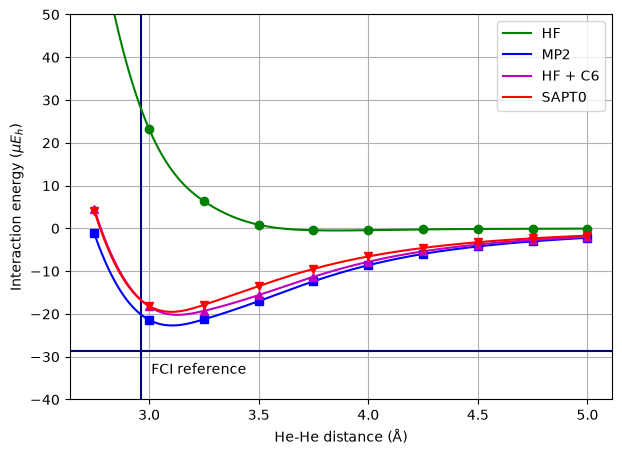

In [ ]:
plt.figure(figsize=(7, 5))

# Reference data at FCI level
plt.axvline(5.6 * au2ang, color="navy")
plt.axhline(-28.76, color="navy")
plt.text(3.01, -34, "FCI reference")

x, y = distances, hf_interaction_energies * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "g-", label="HF")
plt.plot(x, y, "go")

x, y = distances, mp2_interaction_energies * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "b-", label="MP2")
plt.plot(x, y, "bs")

x, y = distances, (hf_interaction_energies - hf_c6 / (distances / au2ang) ** 6) * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "m-", label="HF + C6")
plt.plot(x, y, "m^")

x, y = distances, sapt0_interaction_energies * 1e6
f = scipy.interpolate.interp1d(x, y, kind="cubic")
plt.plot(R, f(R), "r-", label="SAPT0")
plt.plot(x, y, "rv")

plt.xlabel("He-He distance (Å)")
plt.ylabel(r"Interaction energy ($\mu E_h$)")
plt.ylim(-40, 50)
plt.legend()
plt.grid(True)
plt.show()


The minimum of the SAPT0 potential is close to the MP2 and the dispersion-corrected HF results. The similarity to MP2 is not a coincidence, as the uncoupled dispersion term is essentially the intermolecular part of the second-order correlation energy, and SAPT0 and MP2 interaction energies are therefore typically of similar quality for dispersion-bound systems. What is missing compared to FCI is mainly the intramonomer correlation, i.e., the zero in the second superscript of the SAPT0 terms, which affects the monomer charge distributions, and so all contributions.

The real strength of SAPT, however, lies in the *decomposition* of the interaction energy, providing insight into how each term contributes. The decomposition is plotted below, together with the supermolecular results from above.

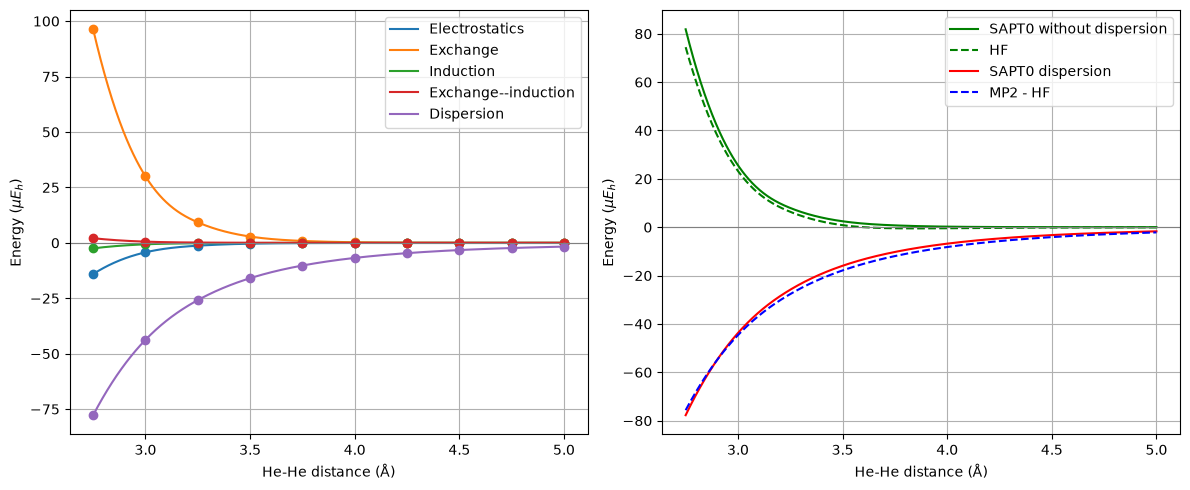

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# SAPT0 terms
labels = {
    "elst": "Electrostatics",
    "exch": "Exchange",
    "ind": "Induction",
    "exch_ind": "Exchange--induction",
    "disp": "Dispersion",
}
for key, label in labels.items():
    x, y = distances, sapt0_terms[key] * 1e6
    f = scipy.interpolate.interp1d(x, y, kind="cubic")
    (line,) = ax1.plot(R, f(R), "-", label=label)
    ax1.plot(x, y, "o", color=line.get_color())

ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_xlabel("He-He distance (Å)")
ax1.set_ylabel(r"Energy ($\mu E_h$)")
ax1.legend()
ax1.grid(True)

# comparison with HF and MP2 results
sapt0_no_disp = (
    sapt0_terms["elst"] + sapt0_terms["exch"] + sapt0_terms["ind"] + sapt0_terms["exch_ind"]
)
curves = [
    (sapt0_no_disp, "g-", "SAPT0 without dispersion"),
    (hf_interaction_energies, "g--", "HF"),
    (sapt0_terms["disp"], "r-", "SAPT0 dispersion"),
    (mp2_interaction_energies - hf_interaction_energies, "b--", "MP2 - HF"),
]
for y, style, label in curves:
    f = scipy.interpolate.interp1d(distances, y * 1e6, kind="cubic")
    ax2.plot(R, f(R), style, label=label)

ax2.axhline(0, color="gray", linewidth=0.8)
ax2.set_xlabel("He-He distance (Å)")
ax2.set_ylabel(r"Energy ($\mu E_h$)")

ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

The decomposition makes clear what we inferred above from the comparison of the HF and MP2 curves. The electrostatic, exchange, induction, and exchange--induction terms add up to a curve that is nearly indistinguishable from the supermolecular HF interaction energy, the difference being the $\delta$HF correction and the $S^2$ approximation. In other wrods, the purely repulsive HF potential results from the exchange term dominating over the (weak) electrostatic attraction. The dispersion term, in turn, closely follows the correlation contribution to the MP2 interaction energy, $\Delta E^\mathrm{MP2} - \Delta E^\mathrm{HF}$. As such, SAPT not only provides interaction energies without the subtraction of large total energies, but also an interpretation of the result in terms of well-defined physical contributions. The dispersion corrections to DFT mentioned above can in this light be seen as adding the one term in this decomposition that approximate exchange--correlation functionals lack.